In [2]:
from sympy.printing.pytorch import torch
%load_ext autoreload
%autoreload 2

In [90]:
import os, random, sys, re
import importlib, traceback
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

import data_loaders
import rs_algorithm.system2.models as models

importlib.reload(data_loaders)
importlib.reload(models)

<module 'rs_algorithm.system2.models' from 'C:\\Beryllium Base\\WORKSPACES\\MTECH\\RS-project\\src\\rs_algorithm\\system2\\models\\__init__.py'>

In [4]:
data_model = data_loaders.MindData(root='../data/mind', specimen='small', split='')

In [46]:
behaviours = data_model.behaviours
print(len(behaviours))
behaviours.head()

156965


,impression_id,user_id,time,history,impressions
0,1,U13740,11/11/2019 9:05:58 AM,N55189 N42782 N34694 N45794 N18445 N63302 N104...,N55689-1 N35729-0
1,2,U91836,11/12/2019 6:11:30 PM,N31739 N6072 N63045 N23979 N35656 N43353 N8129...,N20678-0 N39317-0 N58114-0 N20495-0 N42977-0 N...
2,3,U73700,11/14/2019 7:01:48 AM,N10732 N25792 N7563 N21087 N41087 N5445 N60384...,N50014-0 N23877-0 N35389-0 N49712-0 N16844-0 N...
3,4,U34670,11/11/2019 5:28:05 AM,N45729 N2203 N871 N53880 N41375 N43142 N33013 ...,N35729-0 N33632-0 N49685-1 N27581-0
4,5,U8125,11/12/2019 4:11:21 PM,N10078 N56514 N14904 N33740,N39985-0 N36050-0 N16096-0 N8400-1 N22407-0 N6...


In [47]:
users = behaviours['user_id'].value_counts()
n_users = len(users)
print("Total Users", n_users)
print("Average Trait", users.mean(), users.std())
print(n_users)
users.head()

Total Users 50000
Average Trait 3.1393 3.001025763486988
50000


user_id
U32146    62
U15740    44
U20833    41
U51286    40
U44201    40
Name: count, dtype: int64

In [79]:
str_to_idx = {user: i for i, user in enumerate(users.index)}

In [48]:
behaviours_subset = behaviours[behaviours['user_id'].isin(users[:100].index)]
print(len(behaviours_subset))
behaviours_subset.head()

2813


,impression_id,user_id,time,history,impressions
116,117,U73145,11/11/2019 12:24:31 PM,N21577 N32808 N25908 N45395 N63875 N25008 N389...,N36712-0 N40725-0 N2823-0 N26331-0 N35172-0 N5...
195,196,U20995,11/11/2019 1:50:07 PM,N64727 N44018 N61864 N19760 N5163 N44251 N5518...,N46029-0 N50389-0 N18708-0 N43502-1 N15855-0 N...
213,214,U92991,11/13/2019 2:58:25 PM,N16496 N51591 N43954 N32808 N31457 N5212 N5037...,N8907-0 N7431-0 N23547-0 N27638-0 N48077-0 N16...
214,215,U39701,11/11/2019 1:20:57 PM,N24827 N62931 N62233 N14734 N39556 N22279 N515...,N38662-0 N55689-0 N55204-0 N13930-1
258,259,U16818,11/11/2019 8:35:54 PM,N51591 N44021 N17587 N39074 N39481 N50373 N270...,N50675-1 N54489-0 N16920-0


In [49]:
news = data_model.news
print(len(news))
news.head()

51282


,news_id,category,subcategory,title,abstract,url,title_entities,abstract_entities
0,N55528,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, an...","Shop the notebooks, jackets, and more that the...",https://assets.msn.com/labs/mind/AAGH0ET.html,"[{""Label"": ""Prince Philip, Duke of Edinburgh"",...",[]
1,N19639,health,weightloss,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding yo...,https://assets.msn.com/labs/mind/AAB19MK.html,"[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik...","[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik..."
2,N61837,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches...,Lt. Ivan Molchanets peeked over a parapet of s...,https://assets.msn.com/labs/mind/AAJgNsz.html,[],"[{""Label"": ""Ukraine"", ""Type"": ""G"", ""WikidataId..."
3,N53526,health,voices,I Was An NBA Wife. Here's How It Affected My M...,"I felt like I was a fraud, and being an NBA wi...",https://assets.msn.com/labs/mind/AACk2N6.html,[],"[{""Label"": ""National Basketball Association"", ..."
4,N38324,health,medical,"How to Get Rid of Skin Tags, According to a De...","They seem harmless, but there's a very good re...",https://assets.msn.com/labs/mind/AAAKEkt.html,"[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI...","[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI..."


In [52]:
try:
    print(news['news_id'].size)
    print(news['news_id'].unique().size)
    print(len(news))
except:
    traceback.print_exc()

51282
51282
51282


In [53]:
news_map = pd.crosstab(news['news_id'], news['category'])
print(len(news_map))
news_map.head()

51282


category,autos,entertainment,finance,foodanddrink,health,kids,lifestyle,middleeast,movies,music,news,northamerica,sports,travel,tv,video,weather
news_id,,,,,,,,,,,,,,,,,
N10,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
N100,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
N1000,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
N10000,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
N10001,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0


In [54]:
n_item_feats = len(news_map.columns)
print(n_item_feats)

17


In [13]:
model_factory = models.U2IDPEModelFactory(n_users, n_item_feats)
model = model_factory.create_model()
model

_NowThatsSomeModel(
  (user_embed): _SuperEmbedding(
    (id_embed): Embedding(50000, 128)
  )
  (item_embed): _SuperEmbedding(
    (feat_embed): Sequential(
      (0): Linear(in_features=17, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
    )
  )
)

In [23]:
try:
    _random_user = torch.zeros((1, 1), dtype=torch.long)
    _random_user[0, 0] = random.randint(0, n_users - 1)
    _random_item = torch.rand((1, n_item_feats), dtype=torch.float)
    _output = model.forward(_random_user, _random_item)
except:
    traceback.print_exc()

In [24]:
try:
    print(_output.shape)
except:
    traceback.print_exc()

torch.Size([1, 1])


In [27]:
behaviours_subset_numpy = behaviours_subset.to_numpy()

In [104]:
losses = []

In [140]:
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [120]:
try:
    for row in behaviours_subset_numpy:
        user_id = row[1]
        impressions = [x.split('-') for x in row[4].split(' ')]
        clicks = np.asarray([news_map.loc[x[0]] for x in impressions if x[1] == '1'])
        skips = np.asarray([news_map.loc[x[0]] for x in impressions if x[1] == '0'])
        clicks, skips = torch.asarray(clicks), torch.asarray(skips)
        # print('clicks', clicks.shape, 'skips', skips.shape)
        m, M = min(len(clicks), len(skips)), max(len(clicks), len(skips))
        dip = (3 * m + M) // 4
        clicks = clicks[np.random.randint(0, len(clicks), (dip,))]
        skips = skips[np.random.randint(0, len(skips), (dip,))]
        # print('clicks', clicks.shape, 'skips', skips.shape)
        item_feats = torch.cat([clicks, skips], dim=0).type(torch.float)
        # print(item_feats.shape)
        labels = torch.zeros((len(item_feats), 1))
        labels[:len(clicks)] = 1
        user_ids = torch.zeros((len(item_feats), 1), dtype=torch.long)
        user_ids[:, :] = str_to_idx[user_id]

        _output = model.forward(user_ids, item_feats)

        optimizer.zero_grad()
        loss = criterion(_output, labels)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

except:
    traceback.print_exc()

In [148]:
def hmm(row):
    user_id = row[1]
    impressions = [x.split('-') for x in row[4].split(' ')]
    clicks = np.asarray([news_map.loc[x[0]] for x in impressions if x[1] == '1'])
    skips = np.asarray([news_map.loc[x[0]] for x in impressions if x[1] == '0'])
    clicks, skips = torch.asarray(clicks), torch.asarray(skips)
    # print('clicks', clicks.shape, 'skips', skips.shape)
    m, M = min(len(clicks), len(skips)), max(len(clicks), len(skips))
    dip = (3 * m + M) // 4
    clicks = clicks[np.random.randint(0, len(clicks), (dip,))]
    skips = skips[np.random.randint(0, len(skips), (dip,))]
    # print('clicks', clicks.shape, 'skips', skips.shape)
    item_feats = torch.cat([clicks, skips], dim=0).type(torch.float)
    # print(item_feats.shape)
    labels = torch.zeros((len(item_feats), 1))
    labels[:len(clicks)] = 1
    user_ids = torch.zeros((len(item_feats), 1), dtype=torch.long)
    user_ids[:, :] = str_to_idx[user_id]
    return user_ids, item_feats, labels


try:
    batch = 64
    for _ in range(10):
        for idx in range(1, len(behaviours_subset_numpy), batch):
            rows = behaviours_subset_numpy[idx:idx + batch]

            a_user_ids = []
            a_item_feats = []
            a_labels = []
            for row in rows:
                user_ids, item_feats, labels = hmm(row)
                a_user_ids.append(user_ids)
                a_item_feats.append(item_feats)
                a_labels.append(labels)

            user_ids = torch.cat(a_user_ids, dim=0)
            item_feats = torch.cat(a_item_feats, dim=0)
            labels = torch.cat(a_labels, dim=0)

            _output = model.forward(user_ids, item_feats)

            optimizer.zero_grad()
            loss = criterion(_output, labels)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())

except:
    traceback.print_exc()

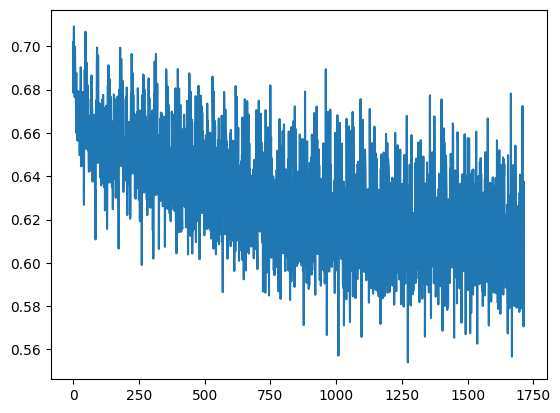

In [150]:
plt.plot(losses[8456:])

In [132]:
len(losses)

8544